# Junta: asistencia marginal no garantiza disponibilidad de quórum

## Resumen
En el caso sintético, independencia de marginales predice0,8512sin reservas yparece cumplir meta0,85; mezcla exacta conausencia común da0,76. Dos participantes dereserva autorizados elevan disponibilidad a0,9139concoste2. No se mide calidad de votos ni aprobación.

## Modelo ycondiciones
Comitébase4, quórumfijo3 ypresencia obligatoria del miembro0(risk_lead). Régimen normalpeso0,8: asistencia(0,95;1;1;1). Disrupción compartidapeso0,2: (0,95;0;0;0). Dentro de cada régimen se asume independencia; incondicionalmente los3miembros comparten ausencia. Reservas autorizadas tienenprobabilidad0,9ysonindependientesdelrégimen por supuesto.

Se enumeran máscarasX∈{0,1}^N ycalculaΣr w_rΣX I(sumX≥3,X0=1)Πi p_ri^Xi(1−p_ri)^(1−Xi). El baseline reemplaza la mezcla porproducto de marginales. Objetivo: menorcoste de reservas que alcanza meta, manteniendo quórum3yrolobligatorio. No se autorizan sustituciones reales por elmodelo.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
cfg=json.loads(Path('config.json').read_text())
summary=json.loads(Path('results/summary.json').read_text())
display(cfg)

{'regimes': [{'name': 'normal', 'weight': 0.8, 'attendance': [0.95, 1, 1, 1]},
  {'name': 'shared_disruption', 'weight': 0.2, 'attendance': [0.95, 0, 0, 0]}],
 'members': ['risk_lead', 'member_A', 'member_B', 'member_C'],
 'quorum': 3,
 'mandatory': [0],
 'standby_menu': [0, 1, 2],
 'standby_attendance': 0.9,
 'unit_standby_cost': 1,
 'target': 0.85,
 'units': 'synthetic availability probability per scheduled session; unit cost arbitrary; authorized extra participants count toward fixed quorum by assumption',
 'hypothesis': 'marginal independence can falsely pass target0.85; exact regime-aware plan reaches target with minimum authorized standbys'}

## Planes ybaseline
Mismas probabilidades marginales, diferente distribución conjunta. Las224filas de máscaras para0/1/2reservas se guardan sin selección, incluidas masas0para conservar elespacio completo.

,standbys,cost,exact_availability,independent_marginal,states
0,0,0,0.7600,0.85120,32
1,1,1,0.7600,0.93328,64
2,2,2,0.9139,0.94764,128


{'selected_exact': {'standbys': 2, 'cost': 2, 'availability': 0.9139},
 'baseline_independent': {'standbys': 0,
  'cost': 0,
  'availability': 0.8512000000000001},
 'actual_baseline_availability': 0.76,
 'independence_error': 0.09120000000000006,
 'seconds': 0.0031936440000208677,
 'python_peak_bytes': 32863,
 'python': '3.12.14',
 'platform': 'Linux-6.18.57-x86_64-with-glibc2.39'}

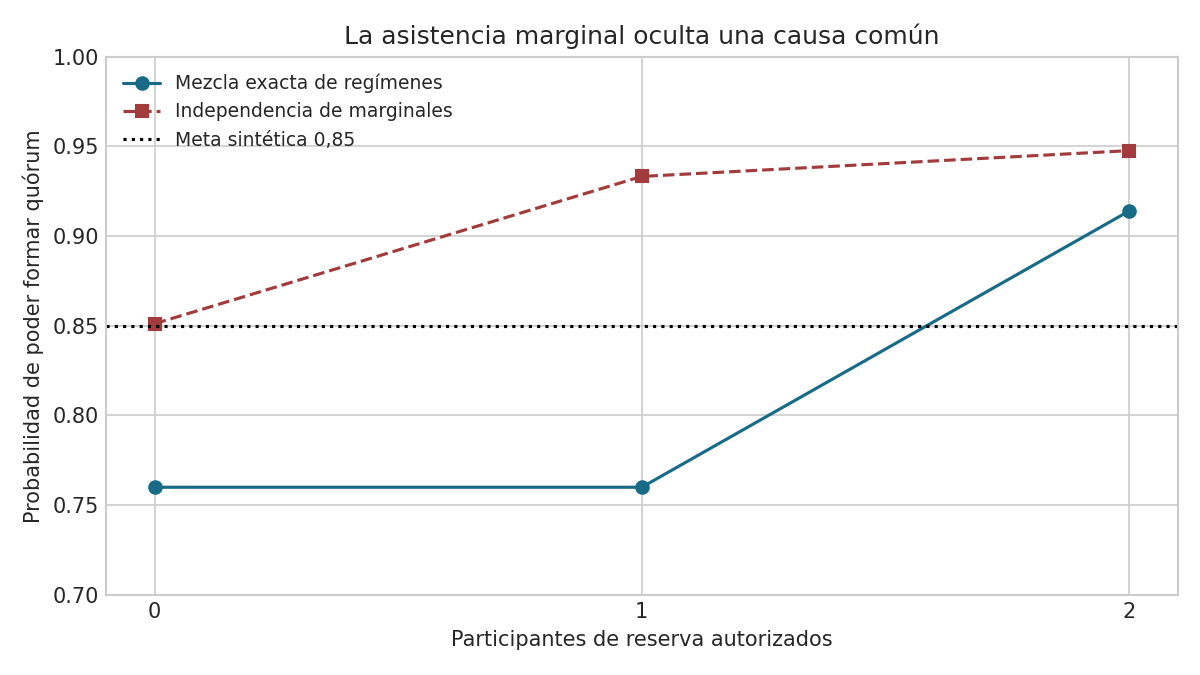

In [2]:
display(pd.read_csv('results/plans.csv').round(5))
display(summary)
display(Image(filename='results/quorum.png'))

## Falsación ylímites
La independencia no falla siempre hacia elmismo lado. Aquí da un falso pase. Elrolobligatorio conprobabilidad0,95limita toda disponibilidad a≤0,95; meta0,97es imposible. Si sube disrupción a0,8, dosreservas tampoco cumplen. Si quórum se eleva a4, no basta este menú. No se baja quórum para forzar factibilidad.

In [3]:
display(pd.read_csv('results/sensitivity.csv'))
display(pd.read_csv('results/scaling.csv'))
assert summary['baseline_independent']['availability']>=cfg['target']>summary['actual_baseline_availability']
assert summary['selected_exact']['availability']>=cfg['target']

,disruption_weight,feasible,standbys,cost,availability
0,0.1,True,0.0,0.0,0.8550
1,0.2,True,2.0,2.0,0.9139
2,0.4,True,2.0,2.0,0.8778
3,0.8,False,NaN,NaN,NaN


,members,states,median_seconds,repetitions
0,4,32,0.000049,5
1,6,128,0.000198,5
2,8,512,0.000920,5


## Decisión
Continuar solo como prueba de resiliencia con2reservas elegibles si reglas vigentes ysupuestos lo permiten. Ajustar calendario/modos remotos si haycorrelación de ausencias. Detener propuesta cuando menú no alcanza meta. No asesoría legal, cambio de estatutos, evidencia de calidad decisional ni probabilidad de aprobación. ComponenteS2 sintético, programa21S1sinrecertificar.

# Iteración 30: investigar el supuesto pendiente del 29

## Pregunta de continuidad
El 29 se fijó asistencia 0,9 de cada reserva en todos los regímenes y se asumió independencia condicional. Su roadmap pidió que las reservas también sufran la disrupción. Hoy conservamos evento, miembros, quórum y rol obligatorio, pero permitimos marginales diferentes durante disrupción y dependencia arbitraria **entre dos reservas**.

Separamos las ablations: recuperar 29 (q=0,9), degradar marginales a 0,7 y después cambiar la distribución conjunta manteniendo esas marginales.

**Antes de calcular:** si ambas reservas asisten con probabilidad 70%, ¿sabemos la probabilidad de que estén las dos? Multiplicar 0,7 por 0,7 exige independencia. Intente construir una tabla 2×2 con esas mismas marginales y otro valor de la celda 11.

## 1. Reducir el modelo original sin cambiar el evento
Sean $Z$ el régimen, $R$ la presencia del responsable de riesgo y $B_1,B_2$ las reservas. El evento sigue siendo
$$E=\{R=1,\ \text{asistentes}\ge3\}.$$
En normal, los tres miembros principales están presentes: solo falta $R$. En disrupción, los tres faltan y se necesitan simultáneamente $R,B_1,B_2$.

Escriba $s=P(Z=\text{disrupción})$ y $r=P(R=1\mid Z)$ constante. Se **mantiene** la independencia de $R$ respecto del par de reservas condicional al régimen. Por probabilidad total:
$$P(E)=(1-s)r+sr\,t=r[(1-s)+st],\qquad t=P(B_1=B_2=1\mid Z=\text{disrupción}).$$
El modelo 29 usaba $t=q_1q_2$. La propuesta sustituye ese supuesto puntual por todos los $t$ compatibles con las marginales, sin modificar el evento.

## 2. Derivar las cotas desde la tabla de estados
Fije $q_1=P(B_1=1\mid Z)$ y $q_2=P(B_2=1\mid Z)$. Si $p_{11}=t$, las otras celdas son
$$p_{10}=q_1-t,\quad p_{01}=q_2-t,\quad p_{00}=1-q_1-q_2+t.$$
Suman uno y reproducen las marginales. La no negatividad implica
$$\max(0,q_1+q_2-1)\le t\le\min(q_1,q_2).$$
Son cotas Fréchet–Hoeffding clásicas, no una fórmula nueva. Son **sharp**: las cuatro celdas construyen una distribución válida en cada extremo. La disponibilidad es lineal creciente en $t$, por lo que
$$L=r[(1-s)+s\max(0,q_1+q_2-1)],\quad U=r[(1-s)+s\min(q_1,q_2)].$$
El oracle LP de los tests minimiza/maximiza $p_{11}$ sujeto a suma uno, marginales y no negatividad, sin usar esta fórmula cerrada.

In [4]:
from src.reserve_ambiguity import ReservePlan, bounds, coupling, nominal_existing_engine
config30=json.loads(Path('config_dependence.json').read_text())
summary30=json.loads(Path('results/dependence_summary.json').read_text())
display(pd.read_csv('results/reserve_couplings.csv'))
p=ReservePlan('exercise',.7,.7,2)
b=bounds(p)
for key in ['lower_joint','independent_joint','upper_joint']:
    masses=coupling(p,b[key])
    assert abs(sum(masses)-1)<1e-12
    assert abs(masses[2]+masses[3]-.7)<1e-12
    assert abs(masses[1]+masses[3]-.7)<1e-12
display(b)

,case,state,probability,q1,q2
0,lower,0,0.00,0.7,0.7
1,lower,1,0.30,0.7,0.7
2,lower,10,0.30,0.7,0.7
3,lower,11,0.40,0.7,0.7
4,independent,0,0.09,0.7,0.7
5,independent,1,0.21,0.7,0.7
6,independent,10,0.21,0.7,0.7
7,independent,11,0.49,0.7,0.7
8,upper_positive,0,0.30,0.7,0.7
9,upper_positive,1,0.00,0.7,0.7


{'lower_joint': 0.3999999999999999,
 'independent_joint': 0.48999999999999994,
 'upper_joint': 0.7,
 'lower_availability': 0.836,
 'nominal_availability': 0.8531,
 'upper_availability': 0.893}

## 3. Separar cambios de marginales y dependencia
- Recuperar 29: q=0,9, nominal 0,9139 y lower 0,912.
- Degradar solo marginales: q=0,7, nominal 0,8531.
- Mismas marginales 0,7, peor dependencia: 0,836, por debajo de meta 0,85.
- Mismas marginales 0,7, dependencia positiva perfecta: 0,893, **mayor** que independencia.

¿Por qué la última mejora? En el régimen crítico se requieren ambas reservas (AND); asistencia conjunta positiva ayuda. No toda correlación empeora disponibilidad. La ausencia común del grupo principal y la dependencia dentro del par son objetos distintos.

,name,q1,q2,cost,lower_joint,independent_joint,upper_joint,lower_availability,nominal_availability,upper_availability,oct29_engine_nominal
0,availability_A,0.7,0.7,2,0.4,0.49,0.7,0.836,0.8531,0.893,0.8531
1,availability_B,0.8,0.8,3,0.6,0.64,0.8,0.874,0.8816,0.912,0.8816
2,availability_C,0.9,0.9,4,0.8,0.81,0.9,0.912,0.9139,0.931,0.9139


{'lower_joint': 0.8,
 'independent_joint': 0.81,
 'upper_joint': 0.9,
 'lower_availability': 0.912,
 'nominal_availability': 0.9139,
 'upper_availability': 0.931}

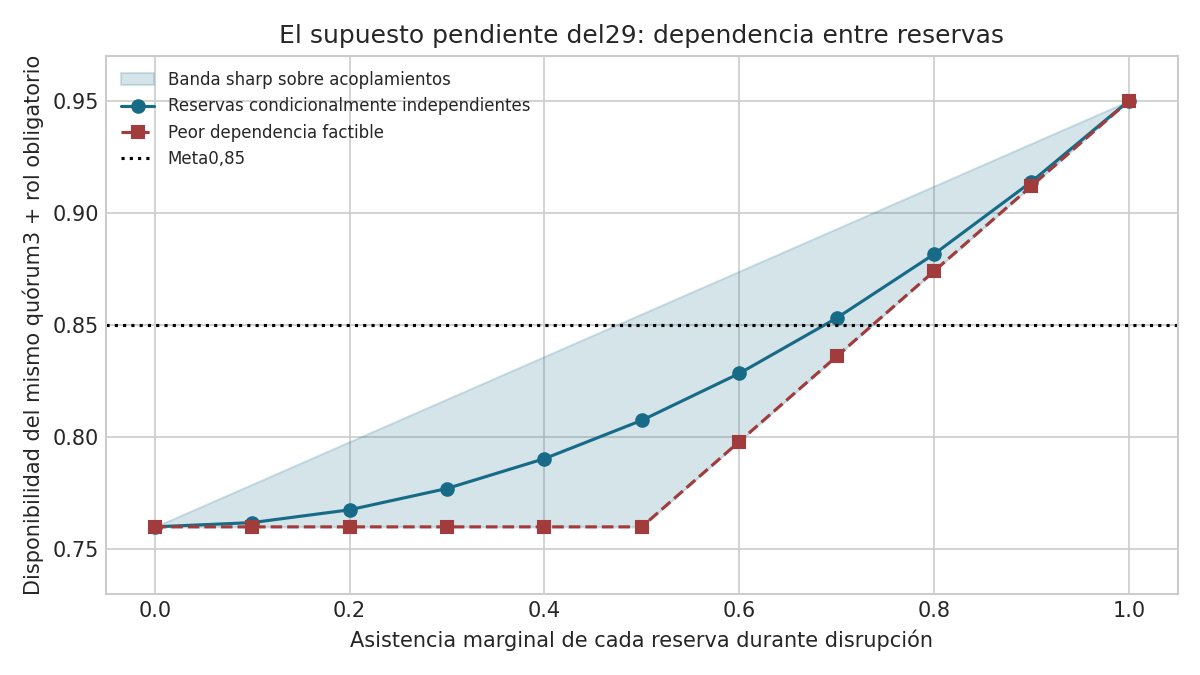

In [5]:
display(pd.read_csv('results/dependence_plans.csv').round(6))
display(summary30['original29_q09_bounds'])
for row in config30['plans']:
    plan=ReservePlan(**row)
    assert abs(nominal_existing_engine(plan)-bounds(plan)['nominal_availability'])<1e-12
display(Image(filename='results/dependence.png'))

## 4. Obtener una frontera de decisión
Para reservas simétricas $q_1=q_2=q$, defina
$$c=\frac{\tau/r-(1-s)}s.$$
Si $0<c\le1$, independencia exige $q^2\ge c$, mientras la garantía sharp exige $2q-1\ge c$:
$$q_{\mathrm{nom}}\ge\sqrt c,\qquad q_{\mathrm{rob}}\ge\frac{1+c}{2}.$$
Con $\tau=0,85$, $r=0,95$ y $s=0,2$: $q_{nom}=0,688247$ frente a $q_{rob}=0,736842$. Si $c\le0$, normal ya basta. Si $c>1$, ni reservas perfectas cubren la meta bajo estos supuestos.

El menú representa opciones hipotéticas, no probabilidades elegidas mágicamente: A(q=0,7,coste 2) pasa nominalmente; B(q=0,8,coste 3) es la mínima que cumple la cota robusta; C(q=0,9,coste 4) también cumple.

In [6]:
display(summary30)
assert summary30['nominal_choice']['name']=='availability_A'
assert summary30['nominal_choice']['nominal_availability']>=.85>summary30['nominal_choice']['lower_availability']
assert summary30['robust_choice']['name']=='availability_B'
assert summary30['robust_choice']['lower_availability']>=.85
display(pd.read_csv('results/dependence_scaling.csv'))

{'nominal_choice': {'name': 'availability_A',
  'cost': 2,
  'lower_availability': 0.836,
  'nominal_availability': 0.8531,
  'upper_availability': 0.893},
 'robust_choice': {'name': 'availability_B',
  'cost': 3,
  'lower_availability': 0.874,
  'nominal_availability': 0.8816,
  'upper_availability': 0.912},
 'critical_nominal_q': 0.6882472016116852,
 'critical_robust_q': 0.7368421052631577,
 'original29_q09_bounds': {'lower_joint': 0.8,
  'independent_joint': 0.81,
  'upper_joint': 0.9,
  'lower_availability': 0.912,
  'nominal_availability': 0.9139,
  'upper_availability': 0.931},
 'seconds': 9.416999995437436e-05,
 'python_peak_bytes': 1160,
 'python': '3.12.14',
 'platform': 'Linux-6.18.57-x86_64-with-glibc2.39'}

,plans,median_seconds,repetitions
0,3,0.000004,5
1,30,0.000031,5
2,300,0.000276,5


## 5. Qué aprendemos y qué queda pendiente
La contribución es una **adaptación operativa de cotas conocidas** a la herramienta 29, con baseline recuperado y menú auditable. No es una copula nueva, probabilidad calibrada o eficacia de gobierno demostrada.

La garantía cubre solamente dependencia entre dos reservas durante disrupción, con marginales y modelo del rol obligatorio fijos. No cubre correlación del responsable de riesgo con reservas, error de marginales, estatutos o calidad de decisiones. El conjunto amplio puede ser conservador: evidencia de dependencia positiva podría estrecharlo.

Antes de una aplicación: justificar elegibilidad, medir marginales durante incidentes e identificar causas compartidas. Consulte matriz_prior_art.md, RESEARCH_LOG.md y ROADMAP.md para clasificación, negativos y pruebas siguientes.